# Major Project Exam: Exploratory Data Analysis (EDA) and Machine Learning Integration

### Problem statement:
Perform a comprehensive analysis on the given dataset using Python, incorporating exploratory data analysis (EDA) and machine learning techniques. Your task is to preprocess the data, engineer features, select and train models, and evaluate their performance. 

##### Additionally, document your process with Python comments explaining your code, and for each section, provide detailed conclusions and observations. 


### Section 1: Understanding the Dataset

#### 1.1	Load Data: Import the dataset into your working environment using appropriate methods or libraries.

In [63]:
#importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#reading the data ets
data = pd.read_csv('car_price_dataset.csv') 

#### 1.2	Checking Data Shape: Determine the shape of your dataset, including the number of rows and columns.

In [64]:
#checking the data shape
data.shape

(15411, 14)

#### 1.3	View Data: Display the first and last few rows of the dataset and summarize any initial insights.

In [65]:
#printing first and last few rows of the dataset
data

,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15406,19537,Hyundai i10,Hyundai,i10,9,10723,Dealer,Petrol,Manual,19.81,1086,68.05,5,250000
15407,19540,Maruti Ertiga,Maruti,Ertiga,2,18000,Dealer,Petrol,Manual,17.50,1373,91.10,7,925000
15408,19541,Skoda Rapid,Skoda,Rapid,6,67000,Dealer,Diesel,Manual,21.14,1498,103.52,5,425000
15409,19542,Mahindra XUV500,Mahindra,XUV500,5,3800000,Dealer,Diesel,Manual,16.00,2179,140.00,7,1225000


In [66]:
data = data.drop(columns=['Unnamed: 0'], errors='ignore')

In [67]:
#conclusion
#The dataset contains 15 411 rows and 14 columns.
#The features are car_name, brand, model, vehicle_age, km_driven, seller_type, fuel_type, transmission_type, mileage, engine, max_power and	seats
#The target is the selling_price

### Section 2: Initial Data Examination

#### 2.1	Dataset Information: Provide a concise summary of the dataset, including the number of non-null entries, and explain what this reveals.

In [68]:
#checking null entries
data.isnull().sum()
#The are no nulls on the dataset

car_name             0
brand                0
model                0
vehicle_age          0
km_driven            0
seller_type          0
fuel_type            0
transmission_type    0
mileage              0
engine               0
max_power            0
seats                0
selling_price        0
dtype: int64

#### 2.2 Inspect Data Types: Check data type of each column in the dataset. If columns need any data type conversion, update the data type accordingly and describe the rationale behind the conversions.

In [69]:
#checking datatypes
data.dtypes

car_name              object
brand                 object
model                 object
vehicle_age            int64
km_driven              int64
seller_type           object
fuel_type             object
transmission_type     object
mileage              float64
engine                 int64
max_power            float64
seats                  int64
selling_price          int64
dtype: object

#### 2.3 Summary Statistics: Generate summary statistics for the numerical columns and interpret what these statistics tell you about the data.

In [70]:
#code for numerical columns
numerical_columns  = data.select_dtypes(include='number')
#droping the column 'Unnamed: 0'
#numerical_columns = numerical_columns.drop(columns='Unnamed: 0')
#describing numerical columns
numerical_columns.describe()

#The average vehicle_age is 6 years and maximum is 29 years, 
#The average Kilometre driven is about 55 616km per car and maximum is 3 800 000km per car,
#The median selling price is 556,000, while the mean is approximately 774,971,
#The lowest selling price is 40,000 and the highest is 39,500,000
#Most cars have 5 seats, but the minimum is 0, which may indicate a data error. 
#Distance driven also has a very high maximum of 3,800,000 km that needs checking.


,vehicle_age,km_driven,mileage,engine,max_power,seats,selling_price
count,15411.000000,1.541100e+04,15411.000000,15411.000000,15411.000000,15411.000000,1.541100e+04
mean,6.036338,5.561648e+04,19.701151,1486.057751,100.588254,5.325482,7.749711e+05
std,3.013291,5.161855e+04,4.171265,521.106696,42.972979,0.807628,8.941284e+05
min,0.000000,1.000000e+02,4.000000,793.000000,38.400000,0.000000,4.000000e+04
25%,4.000000,3.000000e+04,17.000000,1197.000000,74.000000,5.000000,3.850000e+05
50%,6.000000,5.000000e+04,19.670000,1248.000000,88.500000,5.000000,5.560000e+05
75%,8.000000,7.000000e+04,22.700000,1582.000000,117.300000,5.000000,8.250000e+05
max,29.000000,3.800000e+06,33.540000,6592.000000,626.000000,9.000000,3.950000e+07


#### 2.4 Provide detailed comments that explain your understanding of the data.

In [71]:
#The dataset contains 15 411 rows and 14 columns.
#The dataset have features such as car_name, brand, model, vehicle_age, km_driven, seller_type, fuel_type, transmission_type, mileage, engine, max_power and seats
#The target is the selling_price (This what what we are predicting)
#Data has no nulls meaning it ready for other steps of data cleaning
#The average vehicle_age is 6 years and maximum is 29 years, 
#The average Kilometre driven is about 55 616km per car and maximum is 3 800 000km per car,
#The median selling price is 556,000, while the mean is approximately 774,971,
#The lowest selling price is 40,000 and the highest is 39,500,000
#Most cars have 5 seats, but the minimum is 0, which may indicate a data error. 
#Distance driven also has a very high maximum of 3,800,000 km that needs checking.

### Section 3: Data Cleaning

#### 3.1 Handling Missing Values: Identify missing values in the dataset and describe how you handled them, including your chosen method.

In [72]:
#code for missing values
data.isnull().sum()

car_name             0
brand                0
model                0
vehicle_age          0
km_driven            0
seller_type          0
fuel_type            0
transmission_type    0
mileage              0
engine               0
max_power            0
seats                0
selling_price        0
dtype: int64

In [73]:
#there are no missing values
#Therefore i used no methods for handling missing values

#### 3.2 Handling Duplicates: Check for duplicate rows in the dataset and describe your approach to handling any duplicates found.

In [74]:
data.head()

,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


In [75]:
#code for checking duplicates in the dataset
data.duplicated().sum()

np.int64(167)

In [76]:
#code for droping duplicates
data = data.drop_duplicates()

#For handling the duplicates i removed them from the dataset

In [77]:
#checking the duplicates if they have been removedS
data.duplicated().sum()

np.int64(0)

In [78]:
#Checking how many rows are left amd columns
data.shape

(15244, 13)

#### 3.3 Outliers removal: Check if there are any outliers and remove them using graphical/non-graphical methods.

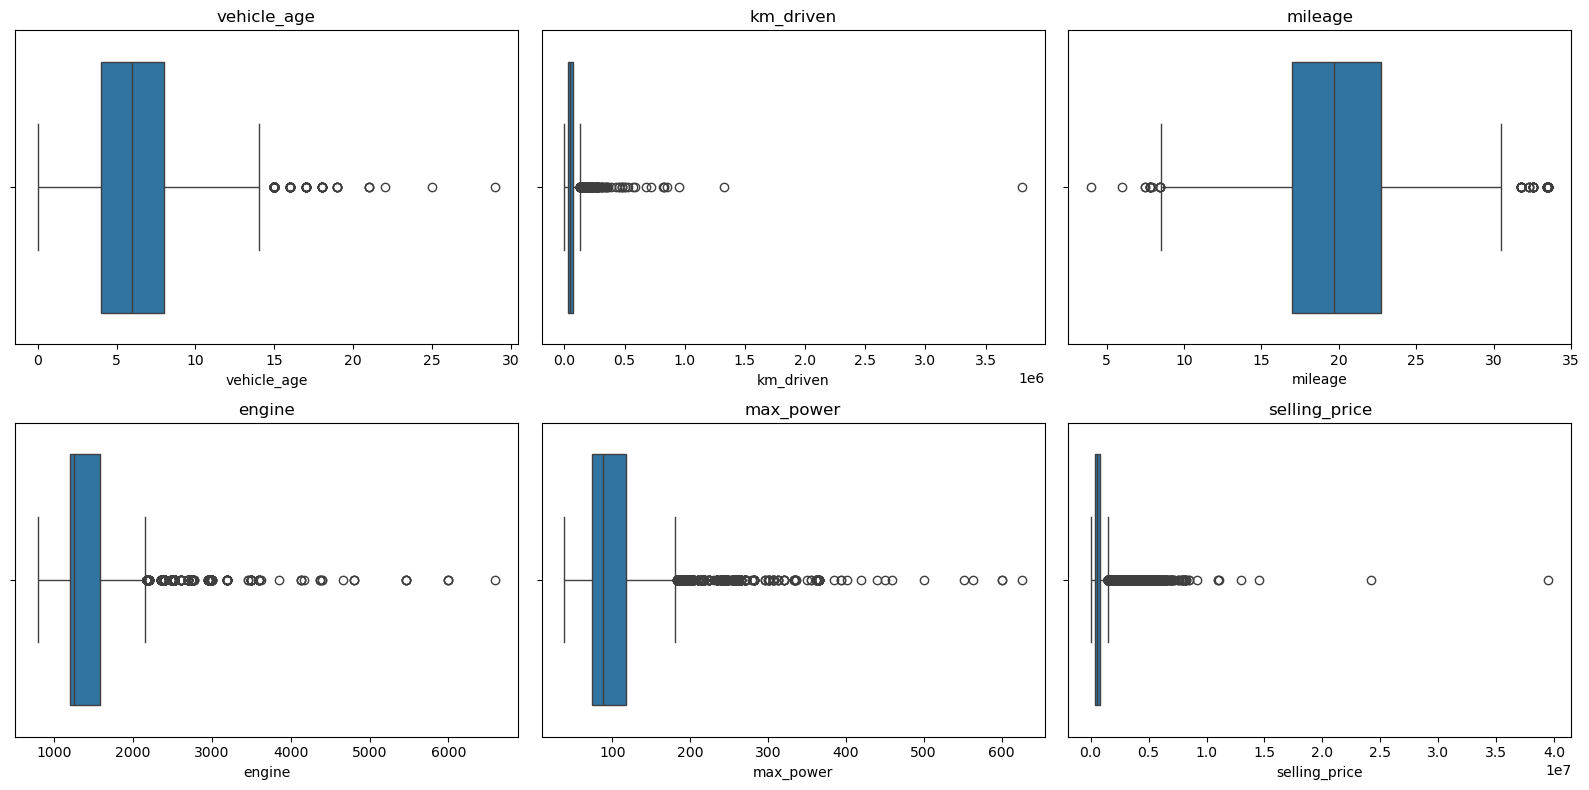

In [79]:
#checking outliers using boxplots
columns = [
    "vehicle_age", "km_driven", "mileage",
    "engine", "max_power", "selling_price"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for ax, column in zip(axes.flat, columns):
    sns.boxplot(x=data[column], ax=ax)
    ax.set_title(column)

plt.tight_layout()

In [80]:
#removing outliers
data_clean = data.loc[
    (data["km_driven"] < 3_800_000) &
    (data["seats"] > 0)
].copy()

print("Rows removed:", len(data) - len(data_clean))
print("Rows remaining:", len(data_clean))

Rows removed: 3
Rows remaining: 15241


In [81]:
#checking number of rows and columns
data_clean.shape

(15241, 13)

#### 3.4 Add python comments to explain the observations.

In [82]:
#We had 167 duplicates in the dataset
#We droped the duplicates
#Boxplots showed extreme values across several numerical columns.
#I inspected the values before removal because expensive or powerful cars can be valid.
#I removed the 3,800,000 km record and two records with zero seats.
#The cleaned dataset contains 15,241 records.

### Section 4: Data Analysis

#### 4.1 Univariate Analysis of numeric features: Generate histograms for numerical data and infer insights from these visualizations.

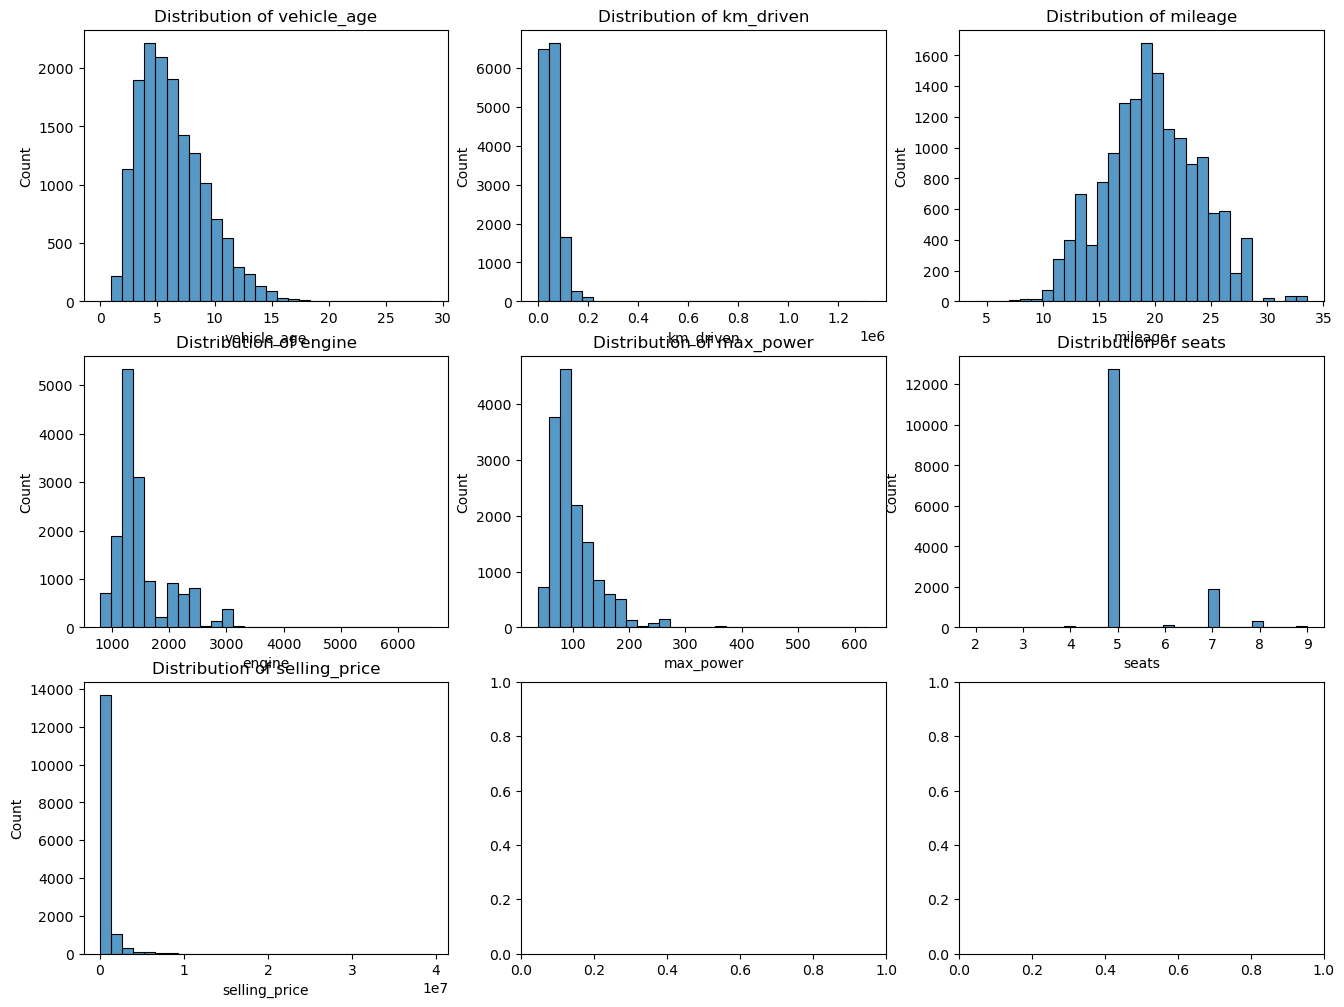

In [83]:
columns = [
    "vehicle_age", "km_driven", "mileage",
    "engine", "max_power", "seats", "selling_price"
]

fig, axes = plt.subplots(3, 3, figsize=(16, 12))

for ax, column in zip(axes.flat, columns):
    sns.histplot(data=data_clean, x=column, bins=30, ax=ax)
    ax.set_title(f"Distribution of {column}")

In [84]:
# Vehicle age: Most cars are approximately 3–9 years old. Older cars are less common.
# Kilometres driven: Most cars have relatively low mileage, with a long right tail
# showing that a small number have travelled much farther.
# Mileage: Values are concentrated around 17–23, with fewer very low or high values.
# Engine size: Smaller engines are common; large engines are less common.
# Maximum power: Most cars have lower to moderate power, with a right tail of powerful cars.
# Seats: Five-seat cars make up the majority of the dataset.
# Selling price: Most cars have lower prices, while a few are very expensive.
# This makes the selling-price distribution strongly right-skewed.

#### 4.2 Examine the skewness in the data and apply appropriate data transformation technique.  

In [85]:
continuous_columns = [
    "vehicle_age", "km_driven", "mileage",
    "engine", "max_power", "selling_price"
]
data_transformed = data_clean.copy()
skewness = data_clean[continuous_columns].skew()
columns_to_transform = skewness[skewness > 1].index.tolist()

for column in columns_to_transform:
    if (data_clean[column] < 0).any():
        print(f"Skipped {column}: it contains negative values")
        continue

    data_transformed[column] = np.log1p(data_clean[column])

print("Columns transformed:", columns_to_transform)
print("\nSkewness before:")
print(skewness[columns_to_transform])
print("\nSkewness after:")
print(data_transformed[columns_to_transform].skew())

Columns transformed: ['km_driven', 'engine', 'max_power', 'selling_price']

Skewness before:
km_driven         6.403813
engine            1.669600
max_power         2.486779
selling_price    10.108923
dtype: float64

Skewness after:
km_driven       -1.052203
engine           0.698956
max_power        0.769910
selling_price    0.565202
dtype: float64


#### 4.3 Apply appropriate standardization method wherever applicable.

In [86]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separating input features from the target
X = data_transformed.drop(columns="selling_price")
y = data_transformed["selling_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scale_columns = [
    "vehicle_age", "km_driven", "mileage",
    "engine", "max_power"
]

scaler = StandardScaler()

X_train = X_train.copy()
X_test = X_test.copy()

# Learn the mean and standard deviation from training data only
X_train[scale_columns] = scaler.fit_transform(X_train[scale_columns])

# Applying those same values to test data
X_test[scale_columns] = scaler.transform(X_test[scale_columns])

X_train[scale_columns].describe().round(2)

,vehicle_age,km_driven,mileage,engine,max_power
count,12192.00,12192.00,12192.00,12192.00,12192.00
mean,-0.00,-0.00,-0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00
min,-2.00,-7.77,-3.28,-1.87,-2.50
25%,-0.67,-0.47,-0.64,-0.54,-0.67
50%,-0.01,0.19,-0.00,-0.40,-0.17
75%,0.65,0.62,0.72,0.37,0.62
max,7.60,4.39,3.33,4.69,5.37


#### 4.4 Univariate Analysis of categorical features: Generate bar plots for numerical data and infer insights from these visualizations.

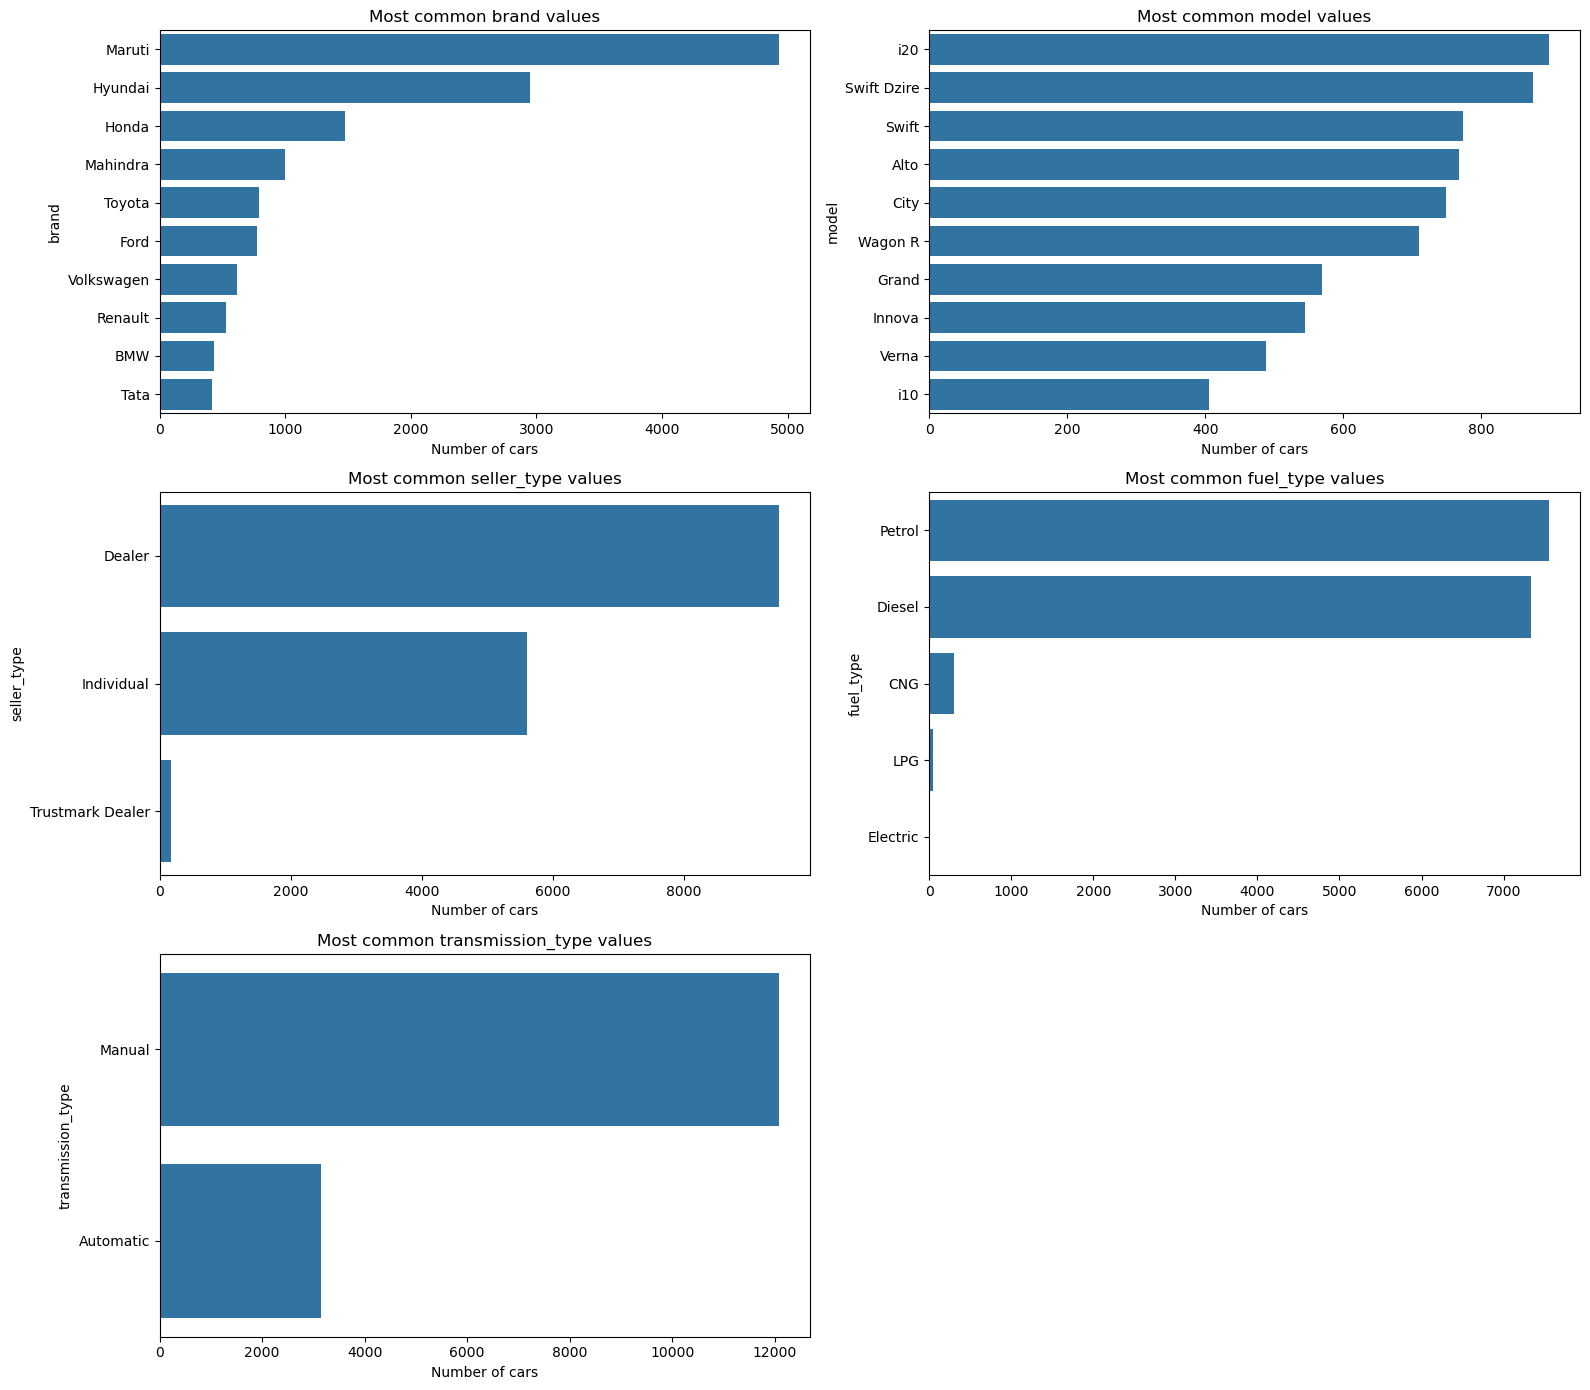

In [87]:
categorical_columns = [
    "brand", "model", "seller_type",
    "fuel_type", "transmission_type"
]

fig, axes = plt.subplots(3, 2, figsize=(16, 14))

for ax, column in zip(axes.flat, categorical_columns):
    # Show the 10 most common categories for columns with many values
    top_categories = data_clean[column].value_counts().head(10).index

    sns.countplot(
        data=data_clean,
        y=column,
        order=top_categories,
        ax=ax
    )
    ax.set_title(f"Most common {column} values")
    ax.set_xlabel("Number of cars")
    ax.set_ylabel(column)

axes.flat[-1].set_visible(False)

plt.tight_layout()
plt.show()

In [88]:
# Maruti is the most common brand, followed by Hyundai.
# A small number of models appear much more frequently than others.
# Dealer listings are more common than individual seller listings.
# Petrol and diesel cars make up nearly all listings; other fuel types are rare.
# Manual cars are much more common than automatic cars.
# These category imbalances should be considered when evaluating the model.

#### 4.5 Encode categorical features

In [89]:
# car_name repeats information already found in brand and model
X_train = X_train.drop(columns="car_name")
X_test = X_test.drop(columns="car_name")

categorical_columns = [
    "brand", "model", "seller_type",
    "fuel_type", "transmission_type"
]

# Create one column per category
X_train = pd.get_dummies(
    X_train,
    columns=categorical_columns,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=categorical_columns,
    dtype=int
)

# Give the test set exactly the same columns and order as the training set
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Columns match:", X_train.columns.equals(X_test.columns))
X_train.head()

Training shape: (12192, 163)
Test shape: (3049, 163)
Columns match: True


,vehicle_age,km_driven,mileage,engine,max_power,seats,brand_Audi,brand_BMW,brand_Bentley,brand_Datsun,...,seller_type_Dealer,seller_type_Individual,seller_type_Trustmark Dealer,fuel_type_CNG,fuel_type_Diesel,fuel_type_Electric,fuel_type_LPG,fuel_type_Petrol,transmission_type_Automatic,transmission_type_Manual
4764,2.306392,1.862744,-1.649376,1.841664,0.230104,7,0,0,0,0,...,1,0,0,0,1,0,0,0,0,1
215,0.651796,0.461728,0.725508,0.190345,-0.127214,5,0,0,0,0,...,1,0,0,0,1,0,0,0,0,1
14494,-0.671881,-0.809084,-0.274822,1.074288,1.952685,5,1,0,0,0,...,1,0,0,0,1,0,0,0,1,0
13432,-0.671881,-0.099911,-0.449940,-0.533430,-0.227268,5,0,0,0,0,...,0,1,0,0,0,0,0,1,0,1
7608,-0.340962,-1.356849,-0.186064,-0.536134,-0.383931,5,0,0,0,0,...,0,1,0,0,0,0,0,1,0,1


#### 4.6 Bivariate and Multivariate Analysis: Calculate the correlation matrix for the numerical variable. Generate heatmap for the correlation matrix, and describe the evident relationships.

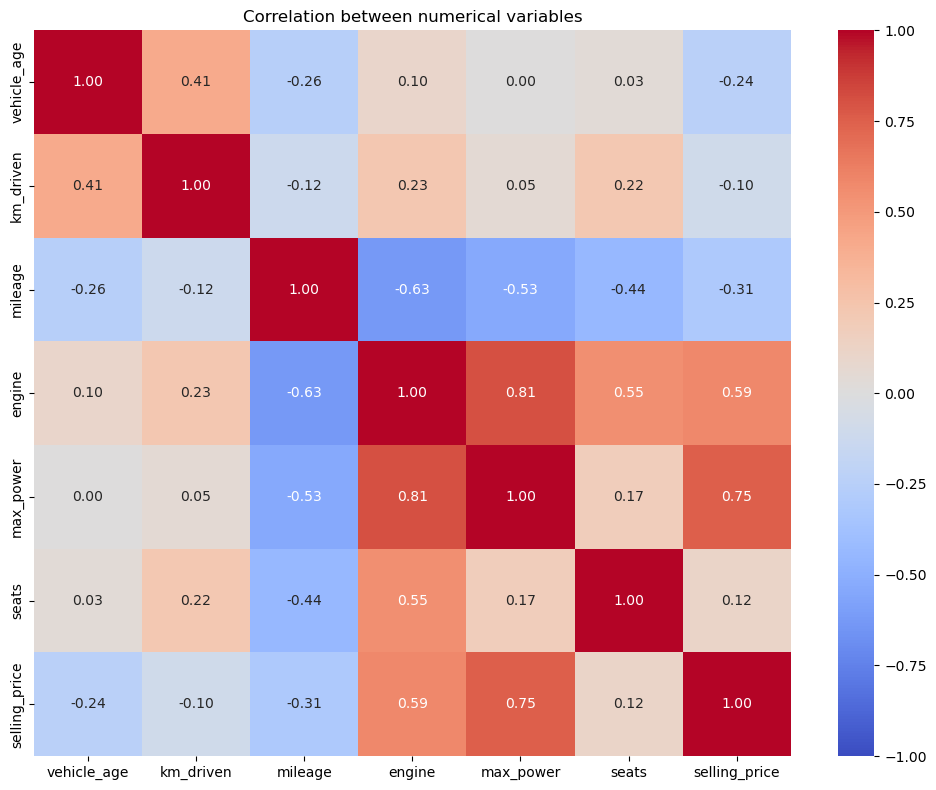

In [90]:
numerical_data = data_clean.select_dtypes(include="number")
correlation_matrix = numerical_data.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.title("Correlation between numerical variables")
plt.tight_layout()
plt.show()

#### 4.7 Provide detailed observations and conclusions.

In [91]:
# Selling price is strongly right-skewed: most cars are in the lower price
# range, while a small number of expensive cars extend the upper tail.
# Kilometres driven, engine size, and maximum power also show right tails.
# Log transformation was used for strongly skewed non-negative columns,
# and continuous input features were standardized for modelling.

# Among numerical variables, max_power has the strongest positive correlation
# with selling_price (about 0.75), followed by engine size (about 0.59).
# Vehicle age has a negative correlation with price (about -0.24).
# The overall correlation between km_driven and price is weak (about -0.10).
# Engine size and max_power are strongly correlated (about 0.81), which may
# matter when interpreting coefficients in a linear regression model.

# These results suggest that power, engine size, age, brand, and model may
# help predict selling price. Correlations alone cannot establish causation
# or show how well a model will perform on unseen cars. The next step is to
# train and evaluate regression models using a held-out test set.

### Section 5: Feature Selection 

#### 5.1 Use correlation result for feature selection.

In [92]:
# Calculate correlation with the target variable
correlation_with_price = data_clean.corr(numeric_only=True)['selling_price'].sort_values(
    ascending=False
)

print(correlation_with_price)

selling_price    1.000000
max_power        0.751068
engine           0.585724
seats            0.115444
km_driven       -0.101102
vehicle_age     -0.241135
mileage         -0.305218
Name: selling_price, dtype: float64


#### 5.2 Select the features according to the K highest score. 

In [93]:
from sklearn.feature_selection import SelectKBest, f_regression

X_numeric = data_clean.select_dtypes(include=['int64', 'float64']).drop(
    columns=['selling_price'],
    errors='ignore'
)

y = data_clean['selling_price']

In [94]:
selector = SelectKBest(score_func=f_regression, k=5)

X_selected = selector.fit_transform(X_numeric, y)

In [95]:
selected_features = X_numeric.columns[selector.get_support()]

print("Selected Features:")
print(selected_features)

Selected Features:
Index(['vehicle_age', 'mileage', 'engine', 'max_power', 'seats'], dtype='object')


In [96]:
feature_scores = pd.DataFrame({
    'Feature': X_numeric.columns,
    'Score': selector.scores_
})

feature_scores = feature_scores.sort_values(
    by='Score',
    ascending=False
)

print(feature_scores)

       Feature         Score
4    max_power  19721.105615
3       engine   7958.374956
2      mileage   1565.476065
0  vehicle_age    940.791921
5        seats    205.837713
1    km_driven    157.375696


#### 5.3 Provide detailed insights about the selected features.

In [97]:
# The feature selection process identified the numerical features
# that have the highest statistical scores in relation to selling_price.
# max_power has the strongest positive relationship with selling_price.
# This indicates that vehicles with higher maximum power generally
# tend to have higher selling prices.
# engine also has a strong positive relationship with selling_price.
# This suggests that vehicles with larger engine capacities generally
# tend to have higher selling prices.
# mileage has a negative relationship with selling_price, indicating
# that vehicles with higher mileage generally tend to have lower prices.
# vehicle_age has a negative relationship with selling_price, suggesting
# that older vehicles generally have lower selling prices due to depreciation.
# km_driven also has a negative relationship with selling_price.
# This indicates that vehicles driven for longer distances may generally
# have lower selling prices.
# Overall, the selected features provide useful information for predicting
# vehicle selling prices. Features related to vehicle performance, such as
# max_power and engine, show stronger relationships with price, while
# vehicle age, mileage and kilometres driven are associated with depreciation.

### Section 6: Model Selection and Training:

#### 6.1 Choose at least three different machine learning algorithms to train on the dataset.

In [98]:
#choosing the three algorithms for traing the model
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

#### 6.2 Train the models and apply hyperparameter tunning.

In [99]:
#code for importing train_test_split
from sklearn.model_selection import train_test_split

X = data_clean[selected_features]
y = data_clean['selling_price']

In [100]:
#spliting data
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size= 0.2, random_state = 42)

In [101]:
#Linear Regression
#choosing model for training 
model = LinearRegression()

#training the model
model.fit(X_train, y_train)

LinearRegression()

In [102]:
#creating predictions of X_test data
y_pred_l = model.predict(X_test)

In [103]:
#decision tree
from sklearn.model_selection import GridSearchCV
#choosing model for training
model_t = DecisionTreeRegressor(random_state=42)

# Define hyperparameters
param_grid_t = {
    'max_depth': [None, 5, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Hyperparameter tuning
grid_t = GridSearchCV(
    estimator=model_t,
    param_grid=param_grid_t,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

#training the model
grid_t.fit(X_train, y_train)


GridSearchCV(cv=5, estimator=DecisionTreeRegressor(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [None, 5, 10, 15, 20],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10]},
             scoring='r2')

In [104]:
# Best Decision Tree model
model_t = grid_t.best_estimator_

# Creating predictions on X_test data
y_pred_t = model_t.predict(X_test)

# Display the best parameters
print("Best Decision Tree Parameters:")
print(grid_t.best_params_)


Best Decision Tree Parameters:
{'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 2}


In [105]:
#creating preditions of X_test data
y_pred_t = model_t.predict(X_test)

In [106]:
#Random forest
#choosing model for training
model_r = RandomForestRegressor(random_state=42)

# Define hyperparameters
param_grid_r = {
    'n_estimators': [100],
    'max_depth': [10, 20],
    'min_samples_split': [2],
    'min_samples_leaf': [1]
}
# Hyperparameter tuning
grid_r = GridSearchCV(
    estimator=model_r,
    param_grid=param_grid_r,
    cv=5,
    scoring='r2',
    n_jobs=-1
)
#training the model
grid_r.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=RandomForestRegressor(random_state=42), n_jobs=-1,
             param_grid={'max_depth': [10, 20], 'min_samples_leaf': [1],
                         'min_samples_split': [2], 'n_estimators': [100]},
             scoring='r2')

In [107]:
# Best Random Forest model
model_r = grid_r.best_estimator_

In [108]:
#creating preditions of X_test data
y_pred_r = model_r.predict(X_test)

#### 6.3 Provide detailed observations and conclusions.

In [109]:
#The three regression models used for predicting car selling prices were
# Linear Regression, Decision Tree Regression, and Random Forest Regression.
# Linear Regression provides a simple baseline model and assumes a linear
# relationship between the selected features and the selling price.
# The Decision Tree Regression model can capture non-linear relationships
# between the features and the selling price by creating decision rules.
# Hyperparameter tuning was applied to identify suitable model parameters
# and improve the model's performance.
# Random Forest Regression combines multiple decision trees to produce more
# robust predictions. Hyperparameter tuning was applied to improve its
# predictive performance and reduce the risk of overfitting.
# The performance of the models should be compared using evaluation metrics
# such as Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean
# Squared Error (RMSE), and R-squared (R²).
# A lower MAE, MSE and RMSE indicates smaller prediction errors, while a
# higher R² indicates that the model explains a greater proportion of the
# variation in selling prices.
# Overall, the model evaluation results will indicate which model is most
# suitable for predicting car selling prices based on the selected features.
# The tuned models are expected to provide improved performance compared
# with their untuned versions.

### Section 7: Model Evaluation:

#### 7.1 Evaluate the performance of each model using appropriate metrics (e.g., accuracy, precision, recall, F1-score for classification; RMSE, MAE, R square for regression).

In [110]:
#importing evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


#for Linear Regression

#MAE
mae_l = mean_absolute_error(y_test , y_pred_l)
#MSE
rmse_l = np.sqrt(mean_squared_error(y_test , y_pred_l))
#R-Squared
r2_score_l = r2_score(y_test, y_pred_l)

#printing results for Linear regression
print("Linear Regression Results")
print("MAE:", mae_l)
print("RMSE:", rmse_l)
print("R²:", r2_score_l)

Linear Regression Results
MAE: 268088.2943806575
RMSE: 774919.1396809497
R²: 0.5263904212975732


In [111]:
#for Decision Tree Regressor

#MAE
mae_t = mean_absolute_error(y_test , y_pred_t)
#MSE
rmse_t= np.sqrt(mean_squared_error(y_test , y_pred_t))
#R-Squared
r2_score_t = r2_score(y_test, y_pred_t)

#printing results for Linear regression
print("Decision Tree Regression Results")
print("MAE:", mae_t)
print("RMSE:", rmse_t)
print("R²:", r2_score_t)

Decision Tree Regression Results
MAE: 119914.38589431359
RMSE: 594975.0926254952
R²: 0.7208065195731864


In [112]:
#for Random Forest Regression

#MAE
mae_r = mean_absolute_error(y_test , y_pred_r)
#MSE
rmse_r= np.sqrt(mean_squared_error(y_test , y_pred_r))
#R-Squared
r2_score_r = r2_score(y_test, y_pred_r)

#printing results for Linear regression
print("Random Forest Regression Results")
print("MAE:", mae_r)
print("RMSE:", rmse_r)
print("R²:", r2_score_r)

Random Forest Regression Results
MAE: 114313.23306906184
RMSE: 618922.5794254912
R²: 0.6978793880056757


#### 7.2 Compare the performance of the models and select the best model based on the evaluation metrics.

In [114]:
# Creating a comparison table
model_comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree Regression', 'Random Forest Regression'],
    'MAE': [mae_l, mae_t, mae_r],
    'RMSE': [rmse_l, rmse_t, rmse_r],
    'R²': [r2_score_l, r2_score_t, r2_score_r]
})

# Displaying the comparison
print("Model Performance Comparison:")
display(model_comparison)

# Identify the best model for each metric
best_mae_model = model_comparison.loc[model_comparison['MAE'].idxmin(), 'Model']
best_rmse_model = model_comparison.loc[model_comparison['RMSE'].idxmin(), 'Model']
best_r2_model = model_comparison.loc[model_comparison['R²'].idxmax(), 'Model']

print("\nBest model based on MAE:", best_mae_model)
print("Best model based on RMSE:", best_rmse_model)
print("Best model based on R²:", best_r2_model)

Model Performance Comparison:


,Model,MAE,RMSE,R²
0,Linear Regression,268088.294381,774919.139681,0.526390
1,Decision Tree Regression,119914.385894,594975.092625,0.720807
2,Random Forest Regression,114313.233069,618922.579425,0.697879



Best model based on MAE: Random Forest Regression
Best model based on RMSE: Decision Tree Regression
Best model based on R²: Decision Tree Regression


#### 7.3 Provide detailed comparison and analysis of the models’ performance.

In [116]:
#
# The three regression models were compared using MAE, RMSE, and R².
#
# Linear Regression:
# MAE  = 268,088.29
# RMSE = 774,919.14
# R²   = 0.526390
#
# Decision Tree Regression:
# MAE  = 119,914.39
# RMSE = 594,975.09
# R²   = 0.720807
#
# Random Forest Regression:
# MAE  = 114,313.23
# RMSE = 618,922.58
# R²   = 0.697879
#
# Linear Regression had the highest MAE and RMSE and the lowest R²,
# indicating that it had the weakest performance among the three models.
#
# Decision Tree Regression performed better than Linear Regression,
# achieving a lower MAE and RMSE and a higher R².
#
# Random Forest Regression achieved the lowest MAE, meaning it had
# the smallest average absolute prediction error.
#
# However, Decision Tree Regression achieved the lowest RMSE and
# the highest R² among the three models.
#
# Therefore, the two tree-based models performed better overall
# than Linear Regression. Random Forest performed best according
# to MAE, while Decision Tree performed best according to RMSE and R².
#
# Based on the overall evaluation metrics, Decision Tree Regression
# is selected as the final model because it achieved the strongest
# performance in two of the three evaluation metrics, particularly
# RMSE and R².



### Section 8: Model Deployment with web app:

#### 8.1: Develop an interactive web application using Streamlit.

#### 8.2 Integrate the best-performing machine learning model into the Streamlit app.

#### 8.3 Provide an interface for users to input new data and obtain predictions from the model.

In [118]:
#Save the trained Decision Tree model for deployment

import joblib

# Save the best-performing Decision Tree model
joblib.dump(model_t, "decision_tree_model.pkl")

print("Decision Tree model saved successfully.")

Decision Tree model saved successfully.


In [119]:
model_t = grid_t.best_estimator_

In [175]:
streamlit_app_code = '''
import streamlit as st
import pandas as pd
import joblib

st.set_page_config(
    page_title="Car Selling Price Prediction",
    page_icon="🚗",
    layout="centered"
)

# Load the trained Decision Tree Regression model
model = joblib.load("decision_tree_model.pkl")

st.title("🚗 Car Selling Price Prediction")
st.write("Enter the vehicle details below to predict its selling price.")

st.subheader("Vehicle Information")

vehicle_age = st.number_input(
    "Vehicle Age (years)", min_value=0.0, max_value=50.0,
    value=5.0, step=1.0
)

mileage = st.number_input(
    "Mileage (km/l)", min_value=0.0, max_value=100.0,
    value=18.0, step=0.1
)

engine = st.number_input(
    "Engine (CC)", min_value=0.0, max_value=10000.0,
    value=1200.0, step=50.0
)

max_power = st.number_input(
    "Max Power (bhp)", min_value=0.0, max_value=2000.0,
    value=80.0, step=1.0
)

seats = st.number_input(
    "Number of Seats", min_value=1, max_value=20,
    value=5, step=1
)

if st.button("Predict Selling Price", type="primary"):
    input_data = pd.DataFrame({
        "vehicle_age": [vehicle_age],
        "mileage": [mileage],
        "engine": [engine],
        "max_power": [max_power],
        "seats": [seats]
    })

    prediction = model.predict(input_data)[0]

    st.success(f"Predicted Selling Price: {prediction:,.2f}")
    st.info("Prediction generated using the Decision Tree Regression model.")
'''

print("Streamlit application code prepared for app.py")

Streamlit application code prepared for app.py
